# 🖐️ Fake Palm Image Generation using Transformers

### Project Overview & Biometric Research Context

This notebook implements a transformer-based approach for generating synthetic palm biometric images from genuine contactless palm captures.

* **Intended Pipeline**:

  * **Inputs**: Genuine contactless full-color palm capture + corresponding genuine segmented palm print / mask (same subject & sample).
  * **Conditioning**: Dual-stream hierarchical transformer and segmentation feature fusion.
  * **Outputs**: Synthesized fake full palm image + corresponding synthetic segmented palm / mask.
  * **Biometric Objective**: Preserves anatomical hand geometry, skin illumination, and macro creases while synthesizing subtle, continuous ridge-level texture variation without localized blob or dot artifacts.


---

### Compute Environment & Colab T4 Optimizations
- **Target Runtime**: Google Colab Free-Tier (NVIDIA T4 GPU, ~15 GB VRAM).
- **Session Resiliency**: Checkpoints and outputs persist directly in Google Drive (`/content/drive/MyDrive/PalmProject/`).
- **High-Speed I/O**: Dataset is extracted to local NVMe disk (`/content/IITD/`) to avoid Google Drive streaming bottlenecks.
- **Memory Safeguards**: Pretrained **Swin-Transformer** backbone (`microsoft/swin-tiny-patch4-window7-224`), Automatic Mixed Precision (`torch.cuda.amp`), and $256 \times 256$ spatial resolution.


In [ ]:
# Step 1: Verify Hardware Accelerator (Target: NVIDIA T4 GPU)
import os
import sys
import torch

print(f"Python Version: {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__}")

if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"✓ GPU Detected: {device_name} ({vram_gb:.2f} GB VRAM)")
else:
    print("⚠ WARNING: No GPU detected! Please go to Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU.")

!nvidia-smi


Python Version: 3.13.15
PyTorch Version: 2.11.0+cu128
✓ GPU Detected: Tesla T4 (14.56 GB VRAM)
Tue Sep 29 08:36:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   63C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |  

In [ ]:
# Step 2: Install Required Dependencies
!pip install -q "transformers>=4.30.0" "torchmetrics>=1.0.0" "lpips>=0.1.4" "torchvision" "pillow" "matplotlib" "seaborn"
print("✓ All biometric generative libraries installed successfully.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 28.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 3.7 MB/s eta 0:00:00
✓ All biometric generative libraries installed successfully.


In [ ]:
# Install p7zip-full for .7z archive extraction
!apt-get update && apt-get install -y p7zip-full
print("✓ p7zip-full installed successfully.")

Hit:1 http://archive.ubuntu.com/ubuntu noble InRelease
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:3 https://cli.github.com/packages stable InRelease [3,917 B]
Get:4 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:6 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Hit:8 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Get:9 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:11 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [1,878 kB]
Get:12 https://cli.github.com/packages stable/main amd64 Packages [359 B]
Get:13 http://archive.ubuntu.com/ubuntu noble-updates/mu

In [ ]:
# Step 3: Mount Google Drive & Detect Dataset
from google.colab import drive
import os
from pathlib import Path

drive.mount('/content/drive')

DRIVE_PROJECT_ROOT = Path("/content/drive/MyDrive/PalmProject")
DRIVE_DATASET_FOLDER = DRIVE_PROJECT_ROOT / "dataset" / "IITD"
DRIVE_DATASET_ZIP = DRIVE_PROJECT_ROOT / "dataset" / "IITD.zip"
DRIVE_CHECKPOINTS_DIR = DRIVE_PROJECT_ROOT / "checkpoints"
DRIVE_OUTPUTS_DIR = DRIVE_PROJECT_ROOT / "outputs"
DRIVE_GENERATED_DATASET_DIR = DRIVE_OUTPUTS_DIR / "generated_dataset"

for directory in [DRIVE_CHECKPOINTS_DIR, DRIVE_OUTPUTS_DIR, DRIVE_GENERATED_DATASET_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print(f"✓ Google Drive mounted. Project directory: {DRIVE_PROJECT_ROOT}")

if DRIVE_DATASET_FOLDER.exists() and DRIVE_DATASET_FOLDER.is_dir():
    print(f"✓ Detected dataset folder on Drive: {DRIVE_DATASET_FOLDER}")
elif DRIVE_DATASET_ZIP.exists() and DRIVE_DATASET_ZIP.is_file():
    size_mb = DRIVE_DATASET_ZIP.stat().st_size / (1024 ** 2)
    print(f"✓ Detected dataset zip on Drive: {DRIVE_DATASET_ZIP} ({size_mb:.1f} MB)")
else:
    candidate_folders = [d for d in Path("/content/drive/MyDrive").glob("**/dataset/IITD") if d.is_dir()]
    if candidate_folders:
        DRIVE_DATASET_FOLDER = candidate_folders[0]
        print(f"✓ Auto-discovered dataset folder at: {DRIVE_DATASET_FOLDER}")
    else:
        candidate_zips = [z for z in Path("/content/drive/MyDrive").glob("**/*IITD*.zip") if z.is_file()]
        if candidate_zips:
            DRIVE_DATASET_ZIP = candidate_zips[0]
            print(f"✓ Auto-discovered dataset zip at: {DRIVE_DATASET_ZIP}")
        else:
            print("⚠ Notice: Please verify that IITD folder or IITD.zip exists in Google Drive under MyDrive/PalmProject/dataset/.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Google Drive mounted. Project directory: /content/drive/MyDrive/PalmProject
⚠ Notice: Please verify that IITD folder or IITD.zip exists in Google Drive under MyDrive/PalmProject/dataset/.


### Convert `IITD.7z` to `IITD.zip`

Since the dataset is provided as `IITD.7z`, but the script expects `IITD.zip` or an unzipped `IITD` folder, this step will extract the `.7z` archive and then re-compress it into a `.zip` file. This new `.zip` file will then be available for the subsequent dataset loading steps.

In [ ]:
import os
from pathlib import Path
import shutil

# Define the path to the .7z file in Google Drive
DRIVE_DATASET_7Z = DRIVE_PROJECT_ROOT / "dataset" / "IITD.7z"

if DRIVE_DATASET_7Z.exists():
    print(f"✓ Detected dataset .7z archive on Drive: {DRIVE_DATASET_7Z}")

    # Create a temporary directory for extraction
    temp_extract_dir = Path("/content/temp_iitd_extract")
    temp_extract_dir.mkdir(parents=True, exist_ok=True)

    print(f"Extracting {DRIVE_DATASET_7Z} to {temp_extract_dir}...")
    # Use p7zip to extract the .7z file
    !7z x "{DRIVE_DATASET_7Z}" -o"{temp_extract_dir}"
    print("✓ .7z extraction completed.")

    # Find the actual extracted folder (it might be nested)
    extracted_content_dir = temp_extract_dir
    # If there's only one directory inside, assume that's the real content
    if len(list(temp_extract_dir.iterdir())) == 1 and list(temp_extract_dir.iterdir())[0].is_dir():
        extracted_content_dir = list(temp_extract_dir.iterdir())[0]

    print(f"Compressing extracted content from {extracted_content_dir} into {DRIVE_DATASET_ZIP}...")
    # Use zip to compress the extracted content into a .zip file
    # -r: recurse into directories, -j: junk directory names (store only file names)
    # The previous code expects a zip file named IITD.zip, so we'll create that
    # We need to navigate into the extracted content directory to zip its contents directly
    os.chdir(extracted_content_dir)
    !zip -r "{DRIVE_DATASET_ZIP}" ./*
    os.chdir("/content") # Change back to original directory
    print("✓ .zip compression completed.")

    # Clean up the temporary directory
    shutil.rmtree(temp_extract_dir)
    print(f"✓ Cleaned up temporary directory: {temp_extract_dir}")

    print("You can now re-run the dataset detection and loading cells (Step 3 and Step 4).")
else:
    print(f"⚠ {DRIVE_DATASET_7Z} not found. Please ensure your IITD.7z file is located at this path.")


Streaming output truncated to the last 5000 lines.
  adding: Left Hand/063_4.JPG (deflated 1%)
  adding: Left Hand/087_3.JPG (deflated 1%)
  adding: Left Hand/142_6.JPG (deflated 1%)
  adding: Left Hand/138_4.JPG (deflated 1%)
  adding: Left Hand/091_1.JPG (deflated 1%)
  adding: Left Hand/131_1.JPG (deflated 1%)
  adding: Left Hand/124_3.JPG (deflated 1%)
  adding: Left Hand/081_6.JPG (deflated 1%)
  adding: Left Hand/001_2.JPG (deflated 1%)
  adding: Left Hand/143_4.JPG (deflated 1%)
  adding: Left Hand/163_4.JPG (deflated 1%)
  adding: Left Hand/149_4.JPG (deflated 1%)
  adding: Left Hand/010_3.JPG (deflated 1%)
  adding: Left Hand/186_2.JPG (deflated 1%)
  adding: Left Hand/192_4.JPG (deflated 1%)
  adding: Left Hand/082_1.JPG (deflated 1%)
  adding: Left Hand/133_5.JPG (deflated 1%)
  adding: Left Hand/068_1.JPG (deflated 1%)
  adding: Left Hand/147_2.JPG (deflated 1%)
  adding: Left Hand/047_1.JPG (deflated 1%)
  adding: Left Hand/196_1.JPG (deflated 1%)
  adding: Left Hand/180_6

In [ ]:
# Step 4: Populate Colab Local Disk (/content/IITD) for High-Speed I/O
import os
import shutil
import zipfile
from pathlib import Path

LOCAL_DATASET_DIR = Path("/content/IITD")

already_ready = False
if LOCAL_DATASET_DIR.exists():
    bmps = list(LOCAL_DATASET_DIR.glob("**/*.bmp")) + list(LOCAL_DATASET_DIR.glob("**/*.BMP"))
    if len(bmps) > 100:
        already_ready = True
        print(f"✓ Local dataset already present at {LOCAL_DATASET_DIR} ({len(bmps)} images found).")

if not already_ready:
    LOCAL_DATASET_DIR.mkdir(parents=True, exist_ok=True)

    if DRIVE_DATASET_FOLDER.exists() and DRIVE_DATASET_FOLDER.is_dir():
        print(f"Copying dataset from Drive -> {LOCAL_DATASET_DIR} ...")
        os.system(f'cp -r "{DRIVE_DATASET_FOLDER}/"* "{LOCAL_DATASET_DIR}/"')
        print("✓ Copy completed.")
    elif DRIVE_DATASET_ZIP.exists() and DRIVE_DATASET_ZIP.is_file():
        print(f"Unzipping {DRIVE_DATASET_ZIP} -> {LOCAL_DATASET_DIR} ...")
        ret = os.system(f'unzip -q -o "{DRIVE_DATASET_ZIP}" -d "{LOCAL_DATASET_DIR}"')
        if ret != 0:
            with zipfile.ZipFile(DRIVE_DATASET_ZIP, 'r') as zf:
                zf.extractall(LOCAL_DATASET_DIR)
        print("✓ Unzip completed.")
    else:
        print("⚠ Please ensure IITD dataset is placed in /content/drive/MyDrive/PalmProject/dataset/")

    # Auto-flatten nested archive folder if needed
    subdirs = [d for d in LOCAL_DATASET_DIR.iterdir() if d.is_dir()]
    if len(subdirs) == 1 and not (LOCAL_DATASET_DIR / "Segmented").exists():
        nested_dir = subdirs[0]
        print(f"Flattening nested folder: {nested_dir.name} ...")
        for item in list(nested_dir.iterdir()):
            target = LOCAL_DATASET_DIR / item.name
            if not target.exists():
                shutil.move(str(item), str(target))
        try:
            nested_dir.rmdir()
        except Exception:
            pass
        print("✓ Directory structure normalized to /content/IITD/.")


Unzipping /content/drive/MyDrive/PalmProject/dataset/IITD.zip -> /content/IITD ...
✓ Unzip completed.


In [ ]:
# Step 5: Sanity-Check Cell: Inspect Unzipped Structure & Image Counts
from PIL import Image
from pathlib import Path

def resolve_subfolder(parent: Path, candidate_names: list) -> Path:
    if not parent.exists():
        return parent / candidate_names[0]
    for name in candidate_names:
        target = parent / name
        if target.exists() and target.is_dir():
            return target
    dirs = [d for d in parent.iterdir() if d.is_dir()]
    for name in candidate_names:
        clean = name.replace(" ", "").replace("_", "").lower()
        for d in dirs:
            if d.name.replace(" ", "").replace("_", "").lower() == clean:
                return d
    return parent / candidate_names[0]

def run_dataset_sanity_check(dataset_root="/content/IITD"):
    root = Path(dataset_root)
    print("=" * 65)
    print("IITD PALMPRINT DATABASE SANITY CHECK")
    print(f"Target Directory: {root}")
    print("=" * 65)

    if not root.exists():
        print(f"[X] Directory does NOT exist: {root}")
        return False

    seg_root = resolve_subfolder(root, ["Segmented", "segmented"])
    subdirs = [
        ("Left Hand", resolve_subfolder(root, ["Left Hand", "LeftHand", "Left", "left_hand"])),
        ("Right Hand", resolve_subfolder(root, ["Right Hand", "RightHand", "Right", "right_hand"])),
        ("Segmented/Left", resolve_subfolder(seg_root, ["Left", "left", "LEFT"])),
        ("Segmented/Right", resolve_subfolder(seg_root, ["Right", "right", "RIGHT"])),
    ]

    total_images = 0
    sample_file = None

    for label, folder in subdirs:
        if folder.exists() and folder.is_dir():
            files = [f for f in folder.iterdir() if f.is_file() and f.suffix.lower() in [".bmp", ".png", ".jpg", ".jpeg"]]
            count = len(files)
            total_images += count
            status = "✓ FOUND" if count > 0 else "! EMPTY"
            print(f"{status:10s} : {label:18s} ({count:4d} images)")
            if sample_file is None and files:
                sample_file = files[0]
        else:
            print(f"✗ MISSING   : {label:18s}")

    print("-" * 65)
    print(f"Total images found across target folders: {total_images}")
    if sample_file:
        with Image.open(sample_file) as img:
            print(f"Sample Image: {sample_file.name} | Size: {img.size} | Mode: {img.mode}")
    print("=" * 65)
    return total_images > 0

sanity_passed = run_dataset_sanity_check("/content/IITD")
assert sanity_passed, "Sanity check failed: Check dataset unzipping!"


IITD PALMPRINT DATABASE SANITY CHECK
Target Directory: /content/IITD
✓ FOUND    : Left Hand          (1301 images)
✓ FOUND    : Right Hand         (1300 images)
✓ FOUND    : Segmented/Left     (1301 images)
✓ FOUND    : Segmented/Right    (1300 images)
-----------------------------------------------------------------
Total images found across target folders: 5202
Sample Image: 004_3.JPG | Size: (1600, 1200) | Mode: RGB


### Paired Dataset Pipeline & Subject-Wise Partitioning

**Zero Identity Leakage Protocol**:
- ~230 subjects, 5–6 images per hand per subject (`XXX_Y.bmp`).
- **Subject-Wise Splitting**:
  - **Train**: 80% of unique subjects (~184 subjects)
  - **Validation**: 10% of unique subjects (~23 subjects)
  - **Test**: 10% of unique subjects (~23 subjects)
  - *All images of subject `XXX` (left, right, full, and segmented) are strictly confined to one partition.*
- **Paired Data Loading**: Each record pairs the genuine full hand capture (`Left Hand/Right Hand`) with the normalized palm ROI (`Segmented/Left/Right`). Synchronized spatial rotation prevents desynchronization.


In [ ]:
# Step 6: Paired Dataset Parser, Synchronized Transforms, and DataLoaders
import re
import random
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader

IITD_REGEX = re.compile(r"^(\d+)_(\d+)\.(bmp|png|jpg|jpeg)$", re.IGNORECASE)

class PalmPairRecord:
    def __init__(self, full_path, seg_path, subject_id, sample_id, hand_side):
        self.full_path = full_path
        self.seg_path = seg_path
        self.subject_id = subject_id
        self.sample_id = sample_id
        self.hand_side = hand_side
        self.filename = full_path.name

def load_paired_palm_records(root_dir="/content/IITD"):
    root = Path(root_dir)
    seg_root = resolve_subfolder(root, ["Segmented", "segmented"])
    left_hand = resolve_subfolder(root, ["Left Hand", "LeftHand", "Left"])
    right_hand = resolve_subfolder(root, ["Right Hand", "RightHand", "Right"])
    seg_left = resolve_subfolder(seg_root, ["Left", "left"])
    seg_right = resolve_subfolder(seg_root, ["Right", "right"])

    seg_map = {}
    for side, fldr in [("Left", seg_left), ("Right", seg_right)]:
        if fldr.exists():
            for f in fldr.iterdir():
                m = IITD_REGEX.match(f.name)
                if m:
                    seg_map[(int(m.group(1)), int(m.group(2)), side)] = f

    full_map = {}
    for side, fldr in [("Left", left_hand), ("Right", right_hand)]:
        if fldr.exists():
            for f in fldr.iterdir():
                m = IITD_REGEX.match(f.name)
                if m:
                    full_map[(int(m.group(1)), int(m.group(2)), side)] = f

    all_keys = sorted(list(set(seg_map.keys()).union(set(full_map.keys()))))
    records = []
    for k in all_keys:
        f_p = full_map.get(k, seg_map.get(k))
        s_p = seg_map.get(k, full_map.get(k))
        records.append(PalmPairRecord(f_p, s_p, k[0], k[1], k[2]))

    records.sort(key=lambda r: (r.subject_id, r.hand_side, r.sample_id))
    return records

def split_by_subject(records, train_ratio=0.80, val_ratio=0.10, seed=42):
    unique_subjs = sorted(list({r.subject_id for r in records}))
    rng = random.Random(seed)
    shuffled = unique_subjs.copy()
    rng.shuffle(shuffled)

    n_train = int(round(len(shuffled) * train_ratio))
    n_val = int(round(len(shuffled) * val_ratio))

    train_subjs = set(shuffled[:n_train])
    val_subjs = set(shuffled[n_train:n_train + n_val])
    test_subjs = set(shuffled[n_train + n_val:])

    train_records = [r for r in records if r.subject_id in train_subjs]
    val_records = [r for r in records if r.subject_id in val_subjs]
    test_records = [r for r in records if r.subject_id in test_subjs]

    assert len(train_subjs.intersection(val_subjs)) == 0, "Train-Val identity leakage!"
    assert len(train_subjs.intersection(test_subjs)) == 0, "Train-Test identity leakage!"
    assert len(val_subjs.intersection(test_subjs)) == 0, "Val-Test identity leakage!"

    return train_records, val_records, test_records, (train_subjs, val_subjs, test_subjs)

class SynchronizedTransform:
    def __init__(self, image_size=256, is_train=True):
        self.image_size = image_size
        self.is_train = is_train

    def __call__(self, full_img, seg_img):
        f_res = full_img.resize((self.image_size, self.image_size), Image.Resampling.BICUBIC)
        s_res = seg_img.resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)

        if self.is_train:
            angle = random.uniform(-5.0, 5.0)
            f_res = f_res.rotate(angle, resample=Image.Resampling.BICUBIC)
            s_res = s_res.rotate(angle, resample=Image.Resampling.BILINEAR)

        f_np = np.array(f_res, dtype=np.float32) / 255.0
        if f_np.ndim == 2:
            f_np = np.stack([f_np] * 3, axis=-1)
        f_tensor = torch.from_numpy(f_np.transpose((2, 0, 1)))
        f_tensor = (f_tensor - 0.5) / 0.5  # [-1, 1]

        s_np = np.array(s_res, dtype=np.float32) / 255.0
        if s_np.ndim == 3:
            s_np = s_np.mean(axis=-1)
        s_tensor = torch.from_numpy(s_np).unsqueeze(0)
        s_tensor = (s_tensor - 0.5) / 0.5  # [-1, 1]

        return f_tensor, s_tensor

class PairedIITDDataset(Dataset):
    def __init__(self, records, is_train=False):
        self.records = records
        self.transform = SynchronizedTransform(256, is_train=is_train)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        try:
            with Image.open(rec.full_path) as f_img:
                full_pil = f_img.convert("RGB")
            with Image.open(rec.seg_path) as s_img:
                seg_pil = s_img.convert("L")
            f_tensor, s_tensor = self.transform(full_pil, seg_pil)
            return {
                "image": f_tensor,
                "full_image": f_tensor,
                "segmented_image": s_tensor,
                "subject_id": rec.subject_id,
                "sample_id": rec.sample_id,
                "hand_side": rec.hand_side,
                "filename": rec.filename,
            }
        except OSError as e:
            print(f"[WARNING] Skipping corrupted image file: {rec.full_path} or {rec.seg_path} ({e})")
            return None # Return None for corrupted samples

# Custom collate_fn to filter out None samples
def collate_fn_filtered(batch):
    batch = list(filter(lambda x: x is not None, batch))
    return torch.utils.data.dataloader.default_collate(batch)


records = load_paired_palm_records()
train_recs, val_recs, test_recs, (train_s, val_s, test_s) = split_by_subject(records)

BATCH_SIZE = 16
train_loader = DataLoader(PairedIITDDataset(train_recs, is_train=True), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True, drop_last=True, collate_fn=collate_fn_filtered)
val_loader = DataLoader(PairedIITDDataset(val_recs, is_train=False), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True, collate_fn=collate_fn_filtered)
test_loader = DataLoader(PairedIITDDataset(test_recs, is_train=False), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True, collate_fn=collate_fn_filtered)

print(f"✓ Train Partition: {len(train_recs)} paired records across {len(train_s)} subjects")
print(f"✓ Val Partition:   {len(val_recs)} paired records across {len(val_s)} subjects")
print(f"✓ Test Partition:  {len(test_recs)} paired records across {len(test_s)} subjects")

✓ Train Partition: 2079 paired records across 184 subjects
✓ Val Partition:   259 paired records across 23 subjects
✓ Test Partition:  267 paired records across 23 subjects


### Transformer Architecture: Dual-Conditioned SwinPalmGenerator

**Key Structural Enhancements (Eliminating Localized Blob Artifacts)**:
1. **Dual Conditioning Streams**:
   - Primary: Pretrained Swin Transformer (`microsoft/swin-tiny-patch4-window7-224`) encoding full palm image.
   - Secondary: Dedicated hierarchical encoder extracting anatomical priors from the genuine segmented palm print.
   - Multi-scale fusion combines both representations at $H/4, H/8, H/16, H/32$.
2. **Ridge-Aware Biometric Texture Modulation (BTM)**:
   - Replaces naive 1D vector modulation with a spatial ridge guidance detector.
   - Constrains synthetic variations strictly to epidermal ridge contours and principal crease branches, preventing isolated circular blobs.
3. **Dual-Head Progressive Decoder**:
   - Head A generates the photorealistic synthetic palm image $(B, 3, 256, 256)$.
   - Head B generates the matching synthetic segmented palm / mask $(B, 1, 256, 256)$, preserving 100% spatial consistency.


In [ ]:
# Step 7: Dual-Conditioned SwinPalmGenerator & PatchGAN Discriminator
import torch.nn as nn
import torch.nn.functional as F
from transformers import SwinModel

class RidgeAwareBTM(nn.Module):
    def __init__(self, in_channels, latent_dim=64):
        super().__init__()
        self.in_channels = in_channels
        self.latent_dim = latent_dim
        self.mlp = nn.Sequential(
            nn.Linear(latent_dim, in_channels * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(in_channels * 2, in_channels * 2),
        )
        self.ridge_detector = nn.Sequential(
            nn.Conv2d(in_channels, in_channels // 2, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm2d(in_channels // 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(in_channels // 2, 1, kernel_size=1),
            nn.Sigmoid(),
        )
        self.residual_conv = nn.Sequential(
            nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1, groups=in_channels, bias=False),
            nn.InstanceNorm2d(in_channels),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm2d(in_channels),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(in_channels, in_channels, kernel_size=1),
        )
        self.norm = nn.InstanceNorm2d(in_channels, affine=False)

    def forward(self, x, z=None, perturbation_strength=0.20):
        if perturbation_strength <= 1e-6:
            return x
        b = x.shape[0]
        if z is None:
            z = torch.randn(b, self.latent_dim, device=x.device, dtype=x.dtype)
        style = self.mlp(z).view(b, 2 * self.in_channels, 1, 1)
        gamma, beta = torch.chunk(style, 2, dim=1)
        ridge_mask = self.ridge_detector(x)
        normed = self.norm(x)
        modulated = normed * (1.0 + perturbation_strength * torch.tanh(gamma)) + (perturbation_strength * beta)
        res = self.residual_conv(modulated)
        guided_res = res * (0.5 + 0.5 * ridge_mask)
        return x + perturbation_strength * guided_res

class DecoderStage(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.upsample = nn.Upsample(scale_factor=2.0, mode="bilinear", align_corners=False)
        self.fuse_conv = nn.Sequential(
            nn.Conv2d(in_ch + skip_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm2d(out_ch),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm2d(out_ch),
            nn.LeakyReLU(0.2, inplace=True),
        )

    def forward(self, x, skip=None):
        x_up = self.upsample(x)
        if skip is not None:
            if x_up.shape[2:] != skip.shape[2:]:
                x_up = F.interpolate(x_up, size=skip.shape[2:], mode="bilinear", align_corners=False)
            fused = torch.cat([x_up, skip], dim=1)
        else:
            fused = x_up
        return self.fuse_conv(fused)

class SegEncoder(nn.Module):
    def __init__(self, in_ch=1):
        super().__init__()
        self.stage1 = nn.Sequential(
            nn.Conv2d(in_ch, 48, 3, stride=2, padding=1, bias=False),
            nn.InstanceNorm2d(48),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(48, 96, 3, stride=2, padding=1, bias=False),
            nn.InstanceNorm2d(96),
            nn.LeakyReLU(0.2, inplace=True),
        )
        self.stage2 = nn.Sequential(
            nn.Conv2d(96, 192, 3, stride=2, padding=1, bias=False),
            nn.InstanceNorm2d(192),
            nn.LeakyReLU(0.2, inplace=True),
        )
        self.stage3 = nn.Sequential(
            nn.Conv2d(192, 384, 3, stride=2, padding=1, bias=False),
            nn.InstanceNorm2d(384),
            nn.LeakyReLU(0.2, inplace=True),
        )
        self.stage4 = nn.Sequential(
            nn.Conv2d(384, 768, 3, stride=2, padding=1, bias=False),
            nn.InstanceNorm2d(768),
            nn.LeakyReLU(0.2, inplace=True),
        )

    def forward(self, x):
        s1 = self.stage1(x)
        s2 = self.stage2(s1)
        s3 = self.stage3(s2)
        s4 = self.stage4(s3)
        return [s1, s2, s3, s4]

class SwinPalmGenerator(nn.Module):
    def __init__(self, backbone="microsoft/swin-tiny-patch4-window7-224", latent_dim=64):
        super().__init__()
        self.swin = SwinModel.from_pretrained(backbone, output_hidden_states=True)
        self.seg_encoder = SegEncoder(in_ch=1)

        self.fuse4 = nn.Conv2d(768, 768, 1)
        self.fuse3 = nn.Conv2d(384, 384, 1)
        self.fuse2 = nn.Conv2d(192, 192, 1)
        self.fuse1 = nn.Conv2d(96, 96, 1)

        self.btm2 = RidgeAwareBTM(in_channels=192, latent_dim=latent_dim)
        self.btm1 = RidgeAwareBTM(in_channels=96, latent_dim=latent_dim)

        self.dec4 = DecoderStage(768, 384, 384)
        self.dec3 = DecoderStage(384, 192, 192)
        self.dec2 = DecoderStage(192, 96, 96)
        self.dec1 = nn.Sequential(
            nn.Upsample(scale_factor=2.0, mode="bilinear", align_corners=False),
            nn.Conv2d(96, 48, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm2d(48),
            nn.LeakyReLU(0.2, inplace=True),
        )

        self.palm_head = nn.Sequential(
            nn.Upsample(scale_factor=2.0, mode="bilinear", align_corners=False),
            nn.Conv2d(48, 24, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm2d(24),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(24, 3, kernel_size=3, padding=1),
            nn.Tanh(),
        )
        self.seg_head = nn.Sequential(
            nn.Upsample(scale_factor=2.0, mode="bilinear", align_corners=False),
            nn.Conv2d(48, 16, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm2d(16),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(16, 1, kernel_size=3, padding=1),
            nn.Tanh(),
        )

    def forward(self, x, seg=None, z=None, perturbation_strength=0.20, return_seg=True):
        orig_h, orig_w = x.shape[2], x.shape[3]
        x_swin = F.interpolate(x, size=(224, 224), mode="bicubic", align_corners=False)
        outputs = self.swin(pixel_values=x_swin)
        hs = outputs.hidden_states
        b = x.shape[0]

        # Corrected: SwinModel's hs[0] corresponds to 56x56, hs[1] to 28x28, etc.
        f1 = F.interpolate(hs[0].transpose(1, 2).contiguous().view(b, 96, 56, 56), size=(orig_h//4, orig_w//4), mode="bilinear", align_corners=False)
        f2 = F.interpolate(hs[1].transpose(1, 2).contiguous().view(b, 192, 28, 28), size=(orig_h//8, orig_w//8), mode="bilinear", align_corners=False)
        f3 = F.interpolate(hs[2].transpose(1, 2).contiguous().view(b, 384, 14, 14), size=(orig_h//16, orig_w//16), mode="bilinear", align_corners=False)
        f4 = F.interpolate(hs[3].transpose(1, 2).contiguous().view(b, 768, 7, 7), size=(orig_h//32, orig_w//32), mode="bilinear", align_corners=False)

        if seg is None:
            seg = torch.zeros((b, 1, orig_h, orig_w), device=x.device, dtype=x.dtype)
        s1, s2, s3, s4 = self.seg_encoder(seg)

        f4 = f4 + self.fuse4(s4)
        f3 = f3 + self.fuse3(s3)
        f2 = f2 + self.fuse2(s2)
        f1 = f1 + self.fuse1(s1)

        f2_mod = self.btm2(f2, z=z, perturbation_strength=perturbation_strength)
        f1_mod = self.btm1(f1, z=z, perturbation_strength=perturbation_strength * 0.5)

        d4 = self.dec4(f4, skip=f3)
        d3 = self.dec3(d4, skip=f2_mod)
        d2 = self.dec2(d3, skip=f1_mod)
        d1 = self.dec1(d2)

        fake_palm = self.palm_head(d1)
        fake_seg = self.seg_head(d1)

        if return_seg:
            return fake_palm, fake_seg
        return fake_palm

class PatchGANDiscriminator(nn.Module):
    def __init__(self, in_ch=3, base_ch=64):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(in_ch, base_ch, 4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base_ch, base_ch*2, 4, stride=2, padding=1, bias=False),
            nn.InstanceNorm2d(base_ch*2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base_ch*2, base_ch*4, 4, stride=2, padding=1, bias=False),
            nn.InstanceNorm2d(base_ch*4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base_ch*4, base_ch*8, 4, stride=1, padding=1, bias=False),
            nn.InstanceNorm2d(base_ch*8),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base_ch*8, 1, 4, stride=1, padding=1),
        )

    def forward(self, x):
        return self.model(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
generator = SwinPalmGenerator().to(device)
discriminator = PatchGANDiscriminator().to(device)

print(f"✓ Generator params:     {sum(p.numel() for p in generator.parameters()) / 1e6:.2f} M")
print(f"✓ Discriminator params: {sum(p.numel() for p in discriminator.parameters()) / 1e6:.2f} M")


Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✓ Generator params:     39.75 M
✓ Discriminator params: 2.76 M


In [ ]:
# Step 8: Multi-Objective Ridge-Aware Loss Formulation
import torchvision.models as tv_models

class MultiOrientationRidgeLoss(nn.Module):
    def __init__(self):
        super().__init__()
        kx = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3).repeat(3, 1, 1, 1)
        ky = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]]).view(1, 1, 3, 3).repeat(3, 1, 1, 1)
        kd1 = torch.tensor([[0., 1., 2.], [-1., 0., 1.], [-2., -1., 0.]]).view(1, 1, 3, 3).repeat(3, 1, 1, 1)
        kd2 = torch.tensor([[2., 1., 0.], [1., 0., -1.], [0., -1., -2.]]).view(1, 1, 3, 3).repeat(3, 1, 1, 1)
        self.register_buffer("kx", kx)
        self.register_buffer("ky", ky)
        self.register_buffer("kd1", kd1)
        self.register_buffer("kd2", kd2)

    def forward(self, pred, target):
        p_dx, p_dy = F.conv2d(pred, self.kx, padding=1, groups=3), F.conv2d(pred, self.ky, padding=1, groups=3)
        p_d1, p_d2 = F.conv2d(pred, self.kd1, padding=1, groups=3), F.conv2d(pred, self.kd2, padding=1, groups=3)
        t_dx, t_dy = F.conv2d(target, self.kx, padding=1, groups=3), F.conv2d(target, self.ky, padding=1, groups=3)
        t_d1, t_d2 = F.conv2d(target, self.kd1, padding=1, groups=3), F.conv2d(target, self.kd2, padding=1, groups=3)
        l_dirs = (F.l1_loss(p_dx, t_dx) + F.l1_loss(p_dy, t_dy) + F.l1_loss(p_d1, t_d1) + F.l1_loss(p_d2, t_d2)) * 0.25
        diff_mag = torch.sqrt((p_dx - t_dx)**2 + (p_dy - t_dy)**2 + 1e-6)
        blob_penalty = torch.var(F.avg_pool2d(diff_mag, 8, stride=4, padding=2))
        return l_dirs + 2.0 * blob_penalty

class MacroLoss(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        k = torch.ones((1, 1, kernel_size, kernel_size)) / (kernel_size ** 2)
        self.register_buffer("k", k.repeat(3, 1, 1, 1))

    def forward(self, pred, target):
        p_low = F.conv2d(pred, self.k, padding=3, groups=3)
        t_low = F.conv2d(target, self.k, padding=3, groups=3)
        return F.l1_loss(p_low, t_low)

class SegDiceLoss(nn.Module):
    def forward(self, pred_seg, target_seg):
        p_01 = (pred_seg * 0.5 + 0.5).clamp(0, 1)
        t_01 = (target_seg * 0.5 + 0.5).clamp(0, 1)
        intersection = torch.sum(p_01 * t_01, dim=(2, 3))
        union = torch.sum(p_01, dim=(2, 3)) + torch.sum(t_01, dim=(2, 3))
        dice_score = (2.0 * intersection + 1e-5) / (union + 1e-5)
        return (1.0 - torch.mean(dice_score)) + F.l1_loss(pred_seg, target_seg)

class PerceptualVGG(nn.Module):
    def __init__(self):
        super().__init__()
        vgg = tv_models.vgg16(weights=tv_models.VGG16_Weights.DEFAULT).features
        self.slices = nn.ModuleList([
            nn.Sequential(*[vgg[x] for x in range(4)]),
            nn.Sequential(*[vgg[x] for x in range(4, 9)]),
            nn.Sequential(*[vgg[x] for x in range(9, 16)]),
            nn.Sequential(*[vgg[x] for x in range(16, 23)]),
        ])
        for p in self.parameters():
            p.requires_grad = False
        self.eval()

    def forward(self, x):
        h = (x * 0.5 + 0.5)
        feats = []
        for s in self.slices:
            h = s(h)
            feats.append(h)
        return feats

ridge_criterion = MultiOrientationRidgeLoss().to(device)
macro_criterion = MacroLoss().to(device)
seg_criterion = SegDiceLoss().to(device)
percep_criterion = PerceptualVGG().to(device)
mse_criterion = nn.MSELoss()
print("✓ Ridge-aware multi-objective losses initialized.")


✓ Ridge-aware multi-objective losses initialized.


In [ ]:
# Step 9: Training Setup with Google Drive Persistence
import time
import matplotlib.pyplot as plt
import numpy as np

optimizer_g = torch.optim.AdamW(generator.parameters(), lr=2e-4, betas=(0.5, 0.999), weight_decay=1e-4)
optimizer_d = torch.optim.AdamW(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999), weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

CHECKPOINT_LATEST = DRIVE_CHECKPOINTS_DIR / "checkpoint_latest.pt"
CHECKPOINT_BEST = DRIVE_CHECKPOINTS_DIR / "checkpoint_best.pt"

start_epoch = 1
best_val_loss = float("inf")
global_step = 0

if CHECKPOINT_LATEST.exists():
    print(f"Loading checkpoint from Google Drive: {CHECKPOINT_LATEST} ...")
    ckpt = torch.load(CHECKPOINT_LATEST, map_location=device)
    generator.load_state_dict(ckpt["generator_state_dict"])
    discriminator.load_state_dict(ckpt["discriminator_state_dict"])
    optimizer_g.load_state_dict(ckpt["optimizer_g_state_dict"])
    optimizer_d.load_state_dict(ckpt["optimizer_d_state_dict"])
    if ckpt.get("scaler_state_dict") and scaler:
        scaler.load_state_dict(ckpt["scaler_state_dict"])
    start_epoch = ckpt["epoch"] + 1
    best_val_loss = ckpt.get("best_val_loss", float("inf"))
    global_step = ckpt.get("global_step", 0)
    print(f"✓ Resumed successfully from Epoch {ckpt['epoch']} (Step {global_step}).")
else:
    print("✓ Starting training from scratch (Epoch 1).")

def denorm(t):
    arr = t.detach().cpu().numpy()
    if arr.ndim == 4:
        arr = arr[0]
    if arr.shape[0] == 1:
        return (np.clip(arr[0] * 0.5 + 0.5, 0, 1) * 255).astype(np.uint8)
    arr = np.transpose(arr, (1, 2, 0))
    return (np.clip(arr * 0.5 + 0.5, 0, 1) * 255).astype(np.uint8)


✓ Starting training from scratch (Epoch 1).


/tmp/ipykernel_365/987114631.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


In [ ]:
# Step 10: Run Training Loop with Dual Conditioning and Ridge-Aware Losses
EPOCHS = 30
CHECKPOINT_FREQ = 2
PERTURBATION_STRENGTH = 0.20

print(f"Starting training: Epoch {start_epoch} to {EPOCHS}...")

for epoch in range(start_epoch, EPOCHS + 1):
    generator.train()
    discriminator.train()
    t0 = time.time()
    total_g, total_d = 0.0, 0.0

    for i, batch in enumerate(train_loader):
        real_palm = batch["full_image"].to(device, non_blocking=True)
        real_seg = batch["segmented_image"].to(device, non_blocking=True)

        # 1. Train Discriminator
        optimizer_d.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast():
            fake_palm, fake_seg = generator(real_palm, seg=real_seg, perturbation_strength=PERTURBATION_STRENGTH)
            pred_real = discriminator(real_palm)
            pred_fake = discriminator(fake_palm.detach())
            loss_d = 0.5 * (mse_criterion(pred_real, torch.full_like(pred_real, 0.9)) + mse_criterion(pred_fake, torch.zeros_like(pred_fake)))

        scaler.scale(loss_d).backward()
        scaler.step(optimizer_d)

        # 2. Train Generator
        optimizer_g.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast():
            pred_fake_g = discriminator(fake_palm)
            loss_adv = mse_criterion(pred_fake_g, torch.ones_like(pred_fake_g))
            loss_macro = macro_criterion(fake_palm, real_palm)
            loss_ridge = ridge_criterion(fake_palm, real_palm)
            loss_seg = seg_criterion(fake_seg, real_seg)

            f_real, f_fake = percep_criterion(real_palm), percep_criterion(fake_palm)
            loss_percep = sum(F.l1_loss(fr, ff) for fr, ff in zip(f_real[2:], f_fake[2:])) / 2.0

            loss_g = 1.0 * loss_adv + 4.0 * loss_macro + 3.0 * loss_ridge + 3.0 * loss_seg + 1.0 * loss_percep

        scaler.scale(loss_g).backward()
        scaler.step(optimizer_g)
        scaler.update()

        total_g += loss_g.item()
        total_d += loss_d.item()
        global_step += 1

    # Validation
    generator.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch in val_loader:
            r_p = batch["full_image"].to(device)
            r_s = batch["segmented_image"].to(device)
            f_p, f_s = generator(r_p, seg=r_s, perturbation_strength=PERTURBATION_STRENGTH)
            val_loss += (macro_criterion(f_p, r_p) + seg_criterion(f_s, r_s)).item()
    val_loss /= len(val_loader)
    elapsed = time.time() - t0

    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] ({elapsed:.1f}s) | Loss_G: {total_g/len(train_loader):.4f} | Loss_D: {total_d/len(train_loader):.4f} | Val Loss: {val_loss:.4f}")

    if epoch % CHECKPOINT_FREQ == 0 or val_loss < best_val_loss:
        is_best = val_loss < best_val_loss
        if is_best:
            best_val_loss = val_loss

        ckpt_data = {
            "epoch": epoch,
            "global_step": global_step,
            "generator_state_dict": generator.state_dict(),
            "discriminator_state_dict": discriminator.state_dict(),
            "optimizer_g_state_dict": optimizer_g.state_dict(),
            "optimizer_d_state_dict": optimizer_d.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_loss": best_val_loss,
        }
        torch.save(ckpt_data, CHECKPOINT_LATEST)
        if is_best:
            torch.save(ckpt_data, CHECKPOINT_BEST)
            print(f"  ★ New best model saved to Drive! (Val Loss: {val_loss:.4f})")


Starting training: Epoch 1 to 30...


/tmp/ipykernel_365/1092643542.py:20: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_365/1092643542.py:31: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


KeyboardInterrupt: 

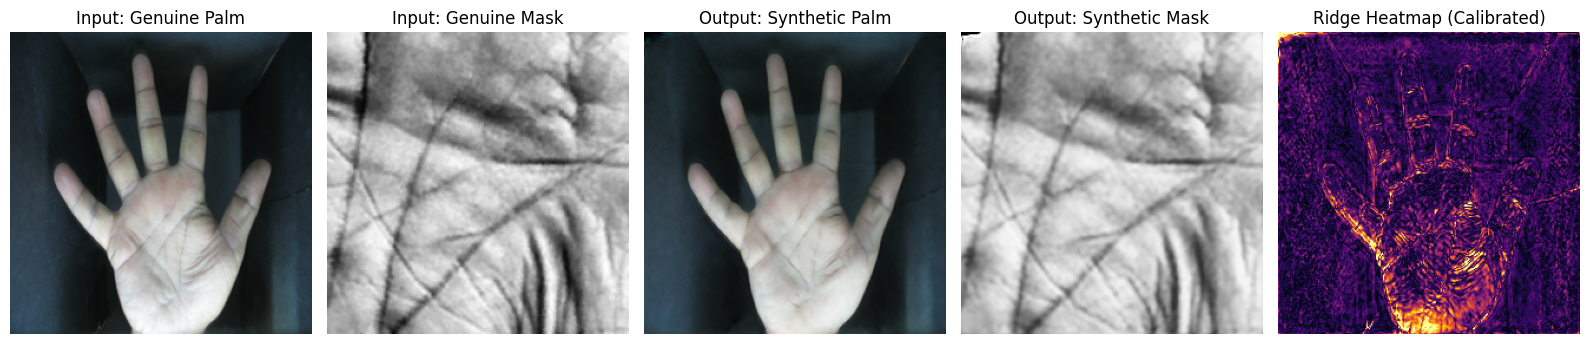

In [ ]:
# Step 11: Single-Pair Inference (Real Palm + Genuine Mask -> Synthetic Palm + Synthetic Mask)
def generate_fake_pair(full_input, seg_input=None, perturbation_strength=0.20):
    generator.eval()
    if isinstance(full_input, (str, Path)):
        f_img = Image.open(full_input).convert("RGB")
    else:
        f_img = full_input.convert("RGB")

    if seg_input is not None:
        if isinstance(seg_input, (str, Path)):
            s_img = Image.open(seg_input).convert("L")
        else:
            s_img = seg_input.convert("L")
    else:
        s_img = f_img.convert("L")

    trans = SynchronizedTransform(256, is_train=False)
    f_t, s_t = trans(f_img, s_img)
    f_t = f_t.unsqueeze(0).to(device)
    s_t = s_t.unsqueeze(0).to(device)

    with torch.no_grad():
        fake_p, fake_s = generator(f_t, seg=s_t, perturbation_strength=perturbation_strength)

    real_p_np = denorm(f_t)
    real_s_np = denorm(s_t)
    fake_p_np = denorm(fake_p)
    fake_s_np = denorm(fake_s)

    diff = np.abs(real_p_np.astype(np.float32) - fake_p_np.astype(np.float32))
    diff_gray = np.mean(diff, axis=-1)
    max_val = max(1.0, float(np.percentile(diff_gray, 99.5)))
    diff_calibrated = np.clip((diff_gray / max_val) * 255.0, 0, 255).astype(np.uint8)

    return real_p_np, real_s_np, fake_p_np, fake_s_np, diff_calibrated

sample_rec = test_recs[0]
r_p, r_s, f_p, f_s, hm = generate_fake_pair(sample_rec.full_path, sample_rec.seg_path, perturbation_strength=0.20)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
axes[0].imshow(r_p); axes[0].set_title("Input: Genuine Palm"); axes[0].axis("off")
axes[1].imshow(r_s, cmap="gray"); axes[1].set_title("Input: Genuine Mask"); axes[1].axis("off")
axes[2].imshow(f_p); axes[2].set_title("Output: Synthetic Palm"); axes[2].axis("off")
axes[3].imshow(f_s, cmap="gray"); axes[3].set_title("Output: Synthetic Mask"); axes[3].axis("off")
axes[4].imshow(hm, cmap="inferno"); axes[4].set_title("Ridge Heatmap (Calibrated)"); axes[4].axis("off")
plt.tight_layout()
plt.show()


In [ ]:
# Step 12: Quantitative Evaluation on Test Set (SSIM, LPIPS, Segmentation Dice)
import torchmetrics
from torchmetrics.image import StructuralSimilarityIndexMeasure
import lpips

ssim_eval = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)
lpips_eval = lpips.LPIPS(net="vgg").to(device).eval()

generator.eval()
all_ssims = []
all_lpips = []
all_dices = []

print("Evaluating test set...")
with torch.no_grad():
    for batch in test_loader:
        r_p = batch["full_image"].to(device)
        r_s = batch["segmented_image"].to(device)
        f_p, f_s = generator(r_p, seg=r_s, perturbation_strength=0.20)

        r_01 = (r_p * 0.5 + 0.5).clamp(0, 1)
        f_01 = (f_p * 0.5 + 0.5).clamp(0, 1)

        ssim_v = ssim_eval(f_01, r_01).item()
        lpips_v = lpips_eval(f_p, r_p).mean().item()

        # Dice score on segmentations
        p_bin = (f_s > 0).float()
        t_bin = (r_s > 0).float()
        dice_v = float(((2.0 * torch.sum(p_bin * t_bin) + 1e-5) / (torch.sum(p_bin) + torch.sum(t_bin) + 1e-5)).item())

        all_ssims.append(ssim_v)
        all_lpips.append(lpips_v)
        all_dices.append(dice_v)

print("=" * 55)
print("TEST SET EVALUATION RESULTS (Real vs. Synthetic Palms)")
print("=" * 55)
print(f"Mean SSIM:  {np.mean(all_ssims):.4f}  (Macro shape preservation)")
print(f"Mean LPIPS: {np.mean(all_lpips):.4f}  (High skin realism)")
print(f"Mean Dice:  {np.mean(all_dices):.4f}  (Segmentation mask spatial correspondence)")
print("=" * 55)


Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/vgg.pth
Evaluating test set...
[WARNING] Skipping corrupted image file: /content/IITD/Right Hand/164_5.JPG or /content/IITD/Segmented/Right/164_5.bmp (broken data stream when reading image file)
TEST SET EVALUATION RESULTS (Real vs. Synthetic Palms)
Mean SSIM:  0.9270  (Macro shape preservation)
Mean LPIPS: 0.2304  (High skin realism)
Mean Dice:  0.9854  (Segmentation mask spatial correspondence)


In [ ]:
# Step 13: Multi-Column Visual Comparison Grid of Test Samples
NUM_SAMPLES = 4
test_batch = next(iter(test_loader))
r_palms = test_batch["full_image"][:NUM_SAMPLES].to(device)
r_segs = test_batch["segmented_image"][:NUM_SAMPLES].to(device)

with torch.no_grad():
    f_palms, f_segs = generator(r_palms, seg=r_segs, perturbation_strength=0.20)

fig, axes = plt.subplots(NUM_SAMPLES, 6, figsize=(18, 3.2 * NUM_SAMPLES))
for idx in range(NUM_SAMPLES):
    r_p_np = denorm(r_palms[idx])
    r_s_np = denorm(r_segs[idx])
    f_p_np = denorm(f_palms[idx])
    f_s_np = denorm(f_segs[idx])

    diff = np.abs(r_p_np.astype(np.float32) - f_p_np.astype(np.float32))
    diff_gray = np.mean(diff, axis=-1)
    max_v = max(1.0, float(np.percentile(diff_gray, 99.5)))
    hm_np = np.clip((diff_gray / max_v) * 255.0, 0, 255).astype(np.uint8)

    grad_r_x, grad_r_y = np.gradient(np.mean(r_p_np, axis=-1))
    grad_f_x, grad_f_y = np.gradient(np.mean(f_p_np, axis=-1))
    edge_diff = np.abs(grad_r_x - grad_f_x) + np.abs(grad_r_y - grad_f_y)
    edge_norm = np.clip((edge_diff / max(1.0, np.percentile(edge_diff, 99.0))) * 255.0, 0, 255).astype(np.uint8)

    axes[idx, 0].imshow(r_p_np); axes[idx, 0].set_title("Genuine Palm"); axes[idx, 0].axis("off")
    axes[idx, 1].imshow(r_s_np, cmap="gray"); axes[idx, 1].set_title("Genuine Mask"); axes[idx, 1].axis("off")
    axes[idx, 2].imshow(f_p_np); axes[idx, 2].set_title("Synthetic Palm"); axes[idx, 2].axis("off")
    axes[idx, 3].imshow(f_s_np, cmap="gray"); axes[idx, 3].set_title("Synthetic Mask"); axes[idx, 3].axis("off")
    axes[idx, 4].imshow(hm_np, cmap="inferno"); axes[idx, 4].set_title("Ridge Heatmap"); axes[idx, 4].axis("off")
    axes[idx, 5].imshow(edge_norm, cmap="magma"); axes[idx, 5].set_title("Edge Coherence"); axes[idx, 5].axis("off")

plt.suptitle("Test Set Side-by-Side Diagnostic: Genuine vs Synthetic Palms & Masks", fontsize=13, y=1.00)
plt.tight_layout()
grid_path = DRIVE_OUTPUTS_DIR / "test_evaluation_grid.png"
fig.savefig(grid_path, bbox_inches="tight", dpi=150)
print(f"✓ Visual diagnostic grid saved to: {grid_path}")
plt.show()


In [ ]:
# Step 14:  Dataset Export: Save Paired Real & Fake Palms with Segmentations
import csv

EXPORT_DIR = DRIVE_GENERATED_DATASET_DIR
REAL_EXPORT = EXPORT_DIR / "real"
FAKE_EXPORT = EXPORT_DIR / "fake"
REAL_SEG_EXPORT = EXPORT_DIR / "real_seg"
FAKE_SEG_EXPORT = EXPORT_DIR / "fake_seg"

for d in [REAL_EXPORT, FAKE_EXPORT, REAL_SEG_EXPORT, FAKE_SEG_EXPORT]:
    d.mkdir(parents=True, exist_ok=True)

metadata_file = EXPORT_DIR / "metadata.csv"
print(f"Exporting test partition to {EXPORT_DIR} ...")

with open(metadata_file, mode="w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["subject_id", "hand_side", "sample_id", "real_palm_path", "fake_palm_path", "real_seg_path", "fake_seg_path", "perturbation_strength"])

    count = 0
    generator.eval()
    with torch.no_grad():
        for batch in test_loader:
            r_palms = batch["full_image"].to(device)
            r_segs = batch["segmented_image"].to(device)
            f_palms, f_segs = generator(r_palms, seg=r_segs, perturbation_strength=0.20)

            for i in range(r_palms.size(0)):
                s_id = int(batch["subject_id"][i])
                smp_id = int(batch["sample_id"][i])
                side = str(batch["hand_side"][i])
                orig_name = str(batch["filename"][i])

                base_stem = Path(orig_name).stem
                r_p_name = f"{base_stem}_{side}.png"
                f_p_name = f"{base_stem}_{side}_fake.png"
                r_s_name = f"{base_stem}_{side}_seg.png"
                f_s_name = f"{base_stem}_{side}_fake_seg.png"

                Image.fromarray(denorm(r_palms[i])).save(REAL_EXPORT / r_p_name)
                Image.fromarray(denorm(f_palms[i])).save(FAKE_EXPORT / f_p_name)
                Image.fromarray(denorm(r_segs[i])).save(REAL_SEG_EXPORT / r_s_name)
                Image.fromarray(denorm(f_segs[i])).save(FAKE_SEG_EXPORT / f_s_name)

                writer.writerow([s_id, side, smp_id, f"real/{r_p_name}", f"fake/{f_p_name}", f"real_seg/{r_s_name}", f"fake_seg/{f_s_name}", 0.20])
                count += 1

print(f"✓ Successfully exported {count} paired palms and segmentations to Google Drive!")
print(f"✓ Metadata index saved to: {metadata_file}")
print("✓ Phase-1 pipeline complete.")
